In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd

file_path = "/content/drive/MyDrive/cryptocast/data/processed/bitcoin_cleaned.csv"

df = pd.read_csv(file_path)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Shape: (4999, 8)
Columns: ['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %', 'Vol_Log']


In [4]:
df['Date'] = pd.to_datetime(df['Date'])

print(df['Date'].dtype)
print(df[['Date', 'Price']].head())

datetime64[ns]
        Date  Price
0 2010-07-18    0.1
1 2010-07-19    0.1
2 2010-07-20    0.1
3 2010-07-21    0.1
4 2010-07-22    0.1


In [5]:
features = ['Price', 'Open', 'High', 'Low', 'Vol_Log', 'Change %']
target = 'Price'

X = df[features]
y = df[target]

print("Features:", features)
print("X shape:", X.shape)
print("y shape:", y.shape)

Features: ['Price', 'Open', 'High', 'Low', 'Vol_Log', 'Change %']
X shape: (4999, 6)
y shape: (4999,)


In [6]:
split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain dates:", train_df['Date'].min(), "to", train_df['Date'].max())
print("Test dates:", test_df['Date'].min(), "to", test_df['Date'].max())

Train shape: (3999, 8)
Test shape: (1000, 8)

Train dates: 2010-07-18 00:00:00 to 2021-06-28 00:00:00
Test dates: 2021-06-29 00:00:00 to 2024-03-24 00:00:00


In [7]:
X_train = train_df[features]
X_test = test_df[features]

y_train = train_df[target]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (3999, 6)
X_test : (1000, 6)
y_train: (3999,)
y_test : (1000,)


In [8]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

y_train_scaled = X_train_scaled[:, 0]
y_test_scaled = X_test_scaled[:, 0]

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)
print("y_train_scaled:", y_train_scaled.shape)
print("y_test_scaled :", y_test_scaled.shape)

X_train_scaled: (3999, 6)
X_test_scaled : (1000, 6)
y_train_scaled: (3999,)
y_test_scaled : (1000,)


In [9]:
import numpy as np


In [10]:
window_size = 60

def create_sequences(data, target, window_size, horizon):
    X_seq = []
    y_seq = []

    for i in range(window_size, len(data) - horizon + 1):
        X_seq.append(data[i-window_size:i])
        y_seq.append(target[i:i+horizon])

    return np.array(X_seq), np.array(y_seq)

In [11]:
X_train_seq_1d, y_train_seq_1d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    1
)

print("X shape:", X_train_seq_1d.shape)
print("y shape:", y_train_seq_1d.shape)

X shape: (3939, 60, 6)
y shape: (3939, 1)


In [12]:
val_size = int(len(X_train_seq_1d) * 0.10)

X_lstm_1d_train = X_train_seq_1d[:-val_size]
y_lstm_1d_train = y_train_seq_1d[:-val_size]

X_lstm_1d_val = X_train_seq_1d[-val_size:]
y_lstm_1d_val = y_train_seq_1d[-val_size:]

print("Training:", X_lstm_1d_train.shape, y_lstm_1d_train.shape)
print("Validation:", X_lstm_1d_val.shape, y_lstm_1d_val.shape)

Training: (3546, 60, 6) (3546, 1)
Validation: (393, 60, 6) (393, 1)


In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

lstm_1d = Sequential([
    Input(shape=(60, 6)),
    LSTM(64, activation='tanh'),
    Dense(64, activation='relu'),
    Dense(1)
])

lstm_1d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

lstm_1d.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,401 (87.50 KB)

 Trainable params: 22,401 (87.50 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history_lstm_1d = lstm_1d.fit(
    X_lstm_1d_train,
    y_lstm_1d_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_lstm_1d_val, y_lstm_1d_val),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - loss: 6.8231e-04 - mae: 0.0146 - val_loss: 0.1396 - val_mae: 0.2912
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 9.8758e-04 - mae: 0.0182 - val_loss: 0.1230 - val_mae: 0.2806
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - loss: 0.0014 - mae: 0.0228 - val_loss: 0.0585 - val_mae: 0.1750
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0013 - mae: 0.0219 - val_loss: 0.0548 - val_mae: 0.1672
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 8.8105e-04 - mae: 0.0191 - val_loss: 0.0211 - val_mae: 0.1004
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 4.5939e-04 - mae: 0.0151 - val_loss: 0.0019 - val_mae: 0.0342
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 2.1284e-04 - mae: 0.0101 - val_loss: 0.0167 - val_mae: 0.0875
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - loss: 2.2636e-04 - mae: 0.0111 - val_loss: 0.0048 - val_mae: 0.0460
Epoch 9/20
111/111 ━━━━━

In [15]:
test_context_X = np.concatenate(
    [X_train_scaled[-window_size:], X_test_scaled],
    axis=0
)

test_context_y = np.concatenate(
    [y_train_scaled[-window_size:], y_test_scaled],
    axis=0
)

X_test_seq_1d, y_test_seq_1d = create_sequences(
    test_context_X,
    test_context_y,
    window_size,
    1
)

print("Test X shape:", X_test_seq_1d.shape)
print("Test y shape:", y_test_seq_1d.shape)

Test X shape: (1000, 60, 6)
Test y shape: (1000, 1)


In [16]:
predictions_1d = lstm_1d.predict(X_test_seq_1d)

print("Prediction shape:", predictions_1d.shape)
print(predictions_1d[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step
Prediction shape: (1000, 1)
[[0.51739496]
 [0.5285774 ]
 [0.53635895]
 [0.53731096]
 [0.5329251 ]]


In [17]:
price_min = scaler.data_min_[0]
price_max = scaler.data_max_[0]

predictions_1d_original = (
    predictions_1d * (price_max - price_min)
) + price_min

actuals_1d_original = (
    y_test_seq_1d * (price_max - price_min)
) + price_min

print("Predicted shape:", predictions_1d_original.shape)
print("Actual shape:", actuals_1d_original.shape)

print("\nFirst 5 Predicted:")
print(predictions_1d_original[:5])

print("\nFirst 5 Actual:")
print(actuals_1d_original[:5])

Predicted shape: (1000, 1)
Actual shape: (1000, 1)

First 5 Predicted:
[[32875.7896697 ]
 [33586.33005304]
 [34080.77693043]
 [34141.26811428]
 [33862.58903275]]

First 5 Actual:
[[35834.7]
 [35026.9]
 [33543.6]
 [33813.4]
 [34742.8]]


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_lstm_1d = mean_absolute_error(
    actuals_1d_original,
    predictions_1d_original
)

rmse_lstm_1d = np.sqrt(
    mean_squared_error(
        actuals_1d_original,
        predictions_1d_original
    )
)

mape_lstm_1d = np.mean(
    np.abs(
        (actuals_1d_original - predictions_1d_original)
        / actuals_1d_original
    )
) * 100

print(f"MAE  : {mae_lstm_1d:.2f}")
print(f"RMSE : {rmse_lstm_1d:.2f}")
print(f"MAPE : {mape_lstm_1d:.2f}%")

MAE  : 1458.14
RMSE : 2208.74
MAPE : 3.80%


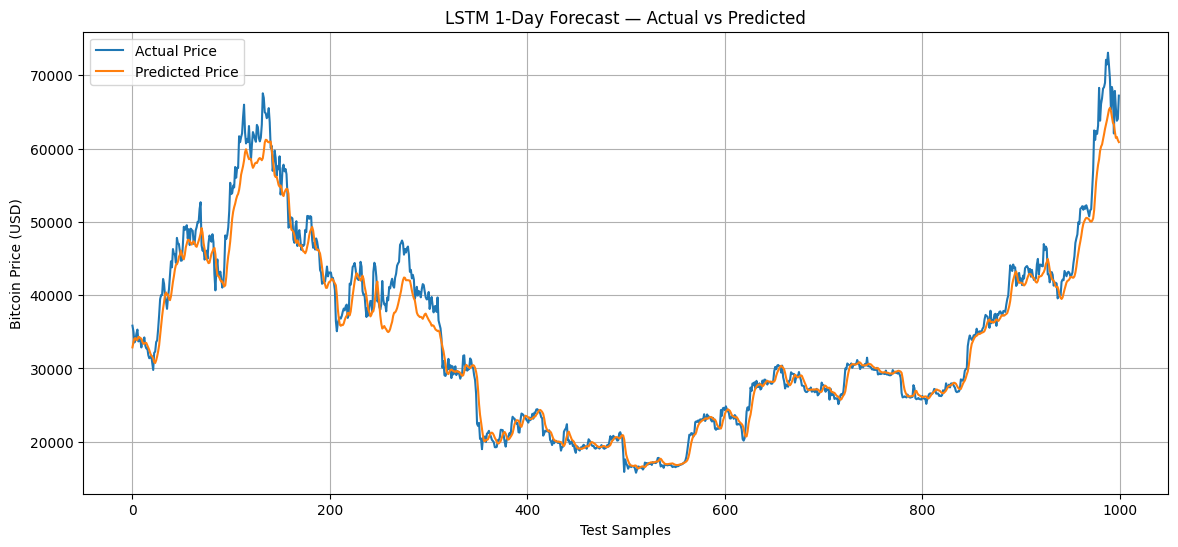

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    actuals_1d_original.flatten(),
    label='Actual Price'
)

plt.plot(
    predictions_1d_original.flatten(),
    label='Predicted Price'
)

plt.title('LSTM 1-Day Forecast — Actual vs Predicted')
plt.xlabel('Test Samples')
plt.ylabel('Bitcoin Price (USD)')
plt.legend()
plt.grid(True)

plt.show()

In [20]:
lstm_1d_results = {
    'Model': 'LSTM',
    'Horizon': '1-Day',
    'MAE': mae_lstm_1d,
    'RMSE': rmse_lstm_1d,
    'MAPE': mape_lstm_1d
}

print(lstm_1d_results)

{'Model': 'LSTM', 'Horizon': '1-Day', 'MAE': 1458.143065522908, 'RMSE': np.float64(2208.7442484971853), 'MAPE': np.float64(3.8030178140837707)}


In [21]:
X_train_seq_3d, y_train_seq_3d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    3
)

print("X shape:", X_train_seq_3d.shape)
print("y shape:", y_train_seq_3d.shape)

X shape: (3937, 60, 6)
y shape: (3937, 3)


In [22]:
val_size = int(len(X_train_seq_3d) * 0.10)

X_lstm_3d_train = X_train_seq_3d[:-val_size]
y_lstm_3d_train = y_train_seq_3d[:-val_size]

X_lstm_3d_val = X_train_seq_3d[-val_size:]
y_lstm_3d_val = y_train_seq_3d[-val_size:]

print("Training:", X_lstm_3d_train.shape, y_lstm_3d_train.shape)
print("Validation:", X_lstm_3d_val.shape, y_lstm_3d_val.shape)

Training: (3544, 60, 6) (3544, 3)
Validation: (393, 60, 6) (393, 3)


In [23]:
lstm_3d = Sequential([
    Input(shape=(60, 6)),
    LSTM(64, activation='tanh'),
    Dense(64, activation='relu'),
    Dense(3)
])

lstm_3d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

lstm_3d.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,531 (88.01 KB)

 Trainable params: 22,531 (88.01 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history_lstm_3d = lstm_3d.fit(
    X_lstm_3d_train,
    y_lstm_3d_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_lstm_3d_val, y_lstm_3d_val),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 7s 46ms/step - loss: 0.0012 - mae: 0.0187 - val_loss: 0.1146 - val_mae: 0.2438
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0015 - mae: 0.0242 - val_loss: 0.1090 - val_mae: 0.2393
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0015 - mae: 0.0244 - val_loss: 0.0551 - val_mae: 0.1638
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - loss: 5.2546e-04 - mae: 0.0151 - val_loss: 0.0322 - val_mae: 0.1239
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - loss: 3.4689e-04 - mae: 0.0120 - val_loss: 0.0215 - val_mae: 0.0971
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 2.5054e-04 - mae: 0.0100 - val_loss: 0.0142 - val_mae: 0.0780
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 1.3054e-04 - mae: 0.0078 - val_loss: 0.0144 - val_mae: 0.0779
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 1.4207e-04 - mae: 0.0074 - val_loss: 0.0111 - val_mae: 0.0681
Epoch 9/20
111/111 ━━━━━━━━━

In [25]:
test_context_X_3d = np.concatenate(
    [X_train_scaled[-window_size:], X_test_scaled],
    axis=0
)

test_context_y_3d = np.concatenate(
    [y_train_scaled[-window_size:], y_test_scaled],
    axis=0
)

X_test_seq_3d, y_test_seq_3d = create_sequences(
    test_context_X_3d,
    test_context_y_3d,
    window_size,
    3
)

print("Test X shape:", X_test_seq_3d.shape)
print("Test y shape:", y_test_seq_3d.shape)

Test X shape: (998, 60, 6)
Test y shape: (998, 3)


In [26]:
predictions_3d = lstm_3d.predict(X_test_seq_3d)

print("Prediction shape:", predictions_3d.shape)
print(predictions_3d[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
Prediction shape: (998, 3)
[[0.605477   0.4774525  0.52499044]
 [0.6173466  0.48845813 0.53551793]
 [0.62577075 0.49551246 0.5416832 ]
 [0.6272672  0.49316722 0.5413212 ]
 [0.62067455 0.48652142 0.5350534 ]]


In [27]:
price_min = scaler.data_min_[0]
price_max = scaler.data_max_[0]

predictions_3d_original = (
    predictions_3d * (price_max - price_min)
) + price_min

actuals_3d_original = (
    y_test_seq_3d * (price_max - price_min)
) + price_min

print("Predicted shape:", predictions_3d_original.shape)
print("Actual shape:", actuals_3d_original.shape)

print("\nFirst 5 Predicted:")
print(predictions_3d_original[:5])

print("\nFirst 5 Actual:")
print(actuals_3d_original[:5])

Predicted shape: (998, 3)
Actual shape: (998, 3)

First 5 Predicted:
[[38472.5914011  30337.8129703  33358.41251278]
 [39226.79587526 31037.12014232 34027.3377491 ]
 [39762.07392302 31485.35784526 34419.0836853 ]
 [39857.15854998 31336.33979082 34396.08324957]
 [39438.25748053 30914.06042585 33997.81932392]]

First 5 Actual:
[[35834.7 35026.9 33543.6]
 [35026.9 33543.6 33813.4]
 [33543.6 33813.4 34742.8]
 [33813.4 34742.8 35298.2]
 [34742.8 35298.2 33687.8]]


In [28]:
lstm_3d_metrics = []

for day in range(3):
    mae = mean_absolute_error(
        actuals_3d_original[:, day],
        predictions_3d_original[:, day]
    )

    rmse = np.sqrt(mean_squared_error(
        actuals_3d_original[:, day],
        predictions_3d_original[:, day]
    ))

    mape = np.mean(
        np.abs(
            (actuals_3d_original[:, day] - predictions_3d_original[:, day])
            / actuals_3d_original[:, day]
        )
    ) * 100

    lstm_3d_metrics.append([day + 1, mae, rmse, mape])

for row in lstm_3d_metrics:
    print(
        f"Day {row[0]} → "
        f"MAE: {row[1]:.2f}, "
        f"RMSE: {row[2]:.2f}, "
        f"MAPE: {row[3]:.2f}%"
    )

Day 1 → MAE: 4470.27, RMSE: 4912.54, MAPE: 13.75%
Day 2 → MAE: 3390.30, RMSE: 4319.67, MAPE: 8.85%
Day 3 → MAE: 1845.97, RMSE: 2838.86, MAPE: 4.87%


In [29]:
actual_flat_3d = actuals_3d_original.flatten()
pred_flat_3d = predictions_3d_original.flatten()

mae_lstm_3d = mean_absolute_error(
    actual_flat_3d,
    pred_flat_3d
)

rmse_lstm_3d = np.sqrt(
    mean_squared_error(
        actual_flat_3d,
        pred_flat_3d
    )
)

mape_lstm_3d = np.mean(
    np.abs(
        (actual_flat_3d - pred_flat_3d)
        / actual_flat_3d
    )
) * 100

print(f"Overall MAE  : {mae_lstm_3d:.2f}")
print(f"Overall RMSE : {rmse_lstm_3d:.2f}")
print(f"Overall MAPE : {mape_lstm_3d:.2f}%")

Overall MAE  : 3235.51
Overall RMSE : 4117.11
Overall MAPE : 9.16%


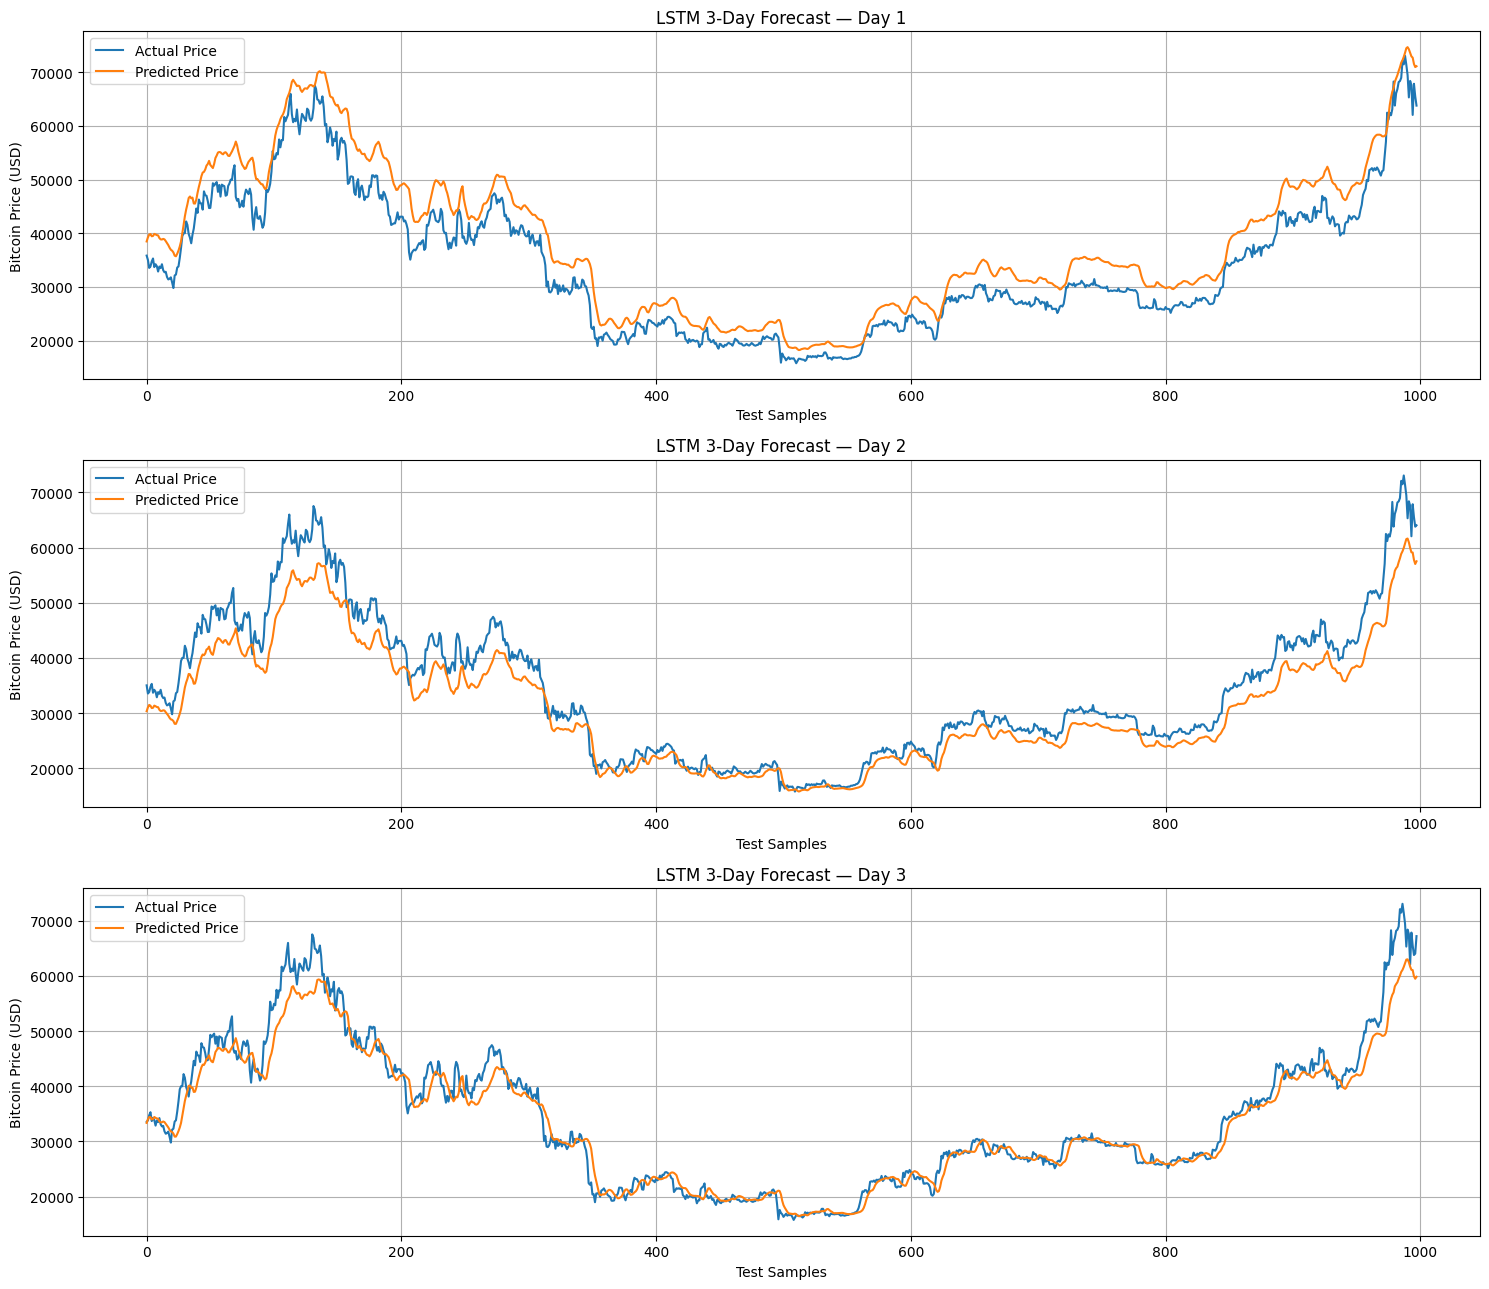

In [30]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(15, 13))

for day in range(3):
    axes[day].plot(
        actuals_3d_original[:, day],
        label='Actual Price'
    )

    axes[day].plot(
        predictions_3d_original[:, day],
        label='Predicted Price'
    )

    axes[day].set_title(
        f'LSTM 3-Day Forecast — Day {day + 1}'
    )
    axes[day].set_xlabel('Test Samples')
    axes[day].set_ylabel('Bitcoin Price (USD)')
    axes[day].legend()
    axes[day].grid(True)

plt.tight_layout()
plt.show()

In [31]:
lstm_3d_results = {
    'Model': 'LSTM',
    'Horizon': '3-Day',
    'MAE': mae_lstm_3d,
    'RMSE': rmse_lstm_3d,
    'MAPE': mape_lstm_3d
}

print(lstm_3d_results)

{'Model': 'LSTM', 'Horizon': '3-Day', 'MAE': 3235.5133530232297, 'RMSE': np.float64(4117.105116754518), 'MAPE': np.float64(9.156400395584123)}


In [32]:
X_train_seq_7d, y_train_seq_7d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    7
)

print("X shape:", X_train_seq_7d.shape)
print("y shape:", y_train_seq_7d.shape)

X shape: (3933, 60, 6)
y shape: (3933, 7)


In [33]:
val_size = int(len(X_train_seq_7d) * 0.10)

X_train_7d = X_train_seq_7d[:-val_size]
y_train_7d = y_train_seq_7d[:-val_size]

X_val_7d = X_train_seq_7d[-val_size:]
y_val_7d = y_train_seq_7d[-val_size:]

print("Training:", X_train_7d.shape, y_train_7d.shape)
print("Validation:", X_val_7d.shape, y_val_7d.shape)

Training: (3540, 60, 6) (3540, 7)
Validation: (393, 60, 6) (393, 7)


In [34]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

lstm_7d = Sequential([
    Input(shape=(60, 6)),
    LSTM(64, activation='tanh'),
    Dense(64, activation='relu'),
    Dense(7)
])

lstm_7d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

lstm_7d.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,791 (89.03 KB)

 Trainable params: 22,791 (89.03 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
history_lstm_7d = lstm_7d.fit(
    X_train_7d,
    y_train_7d,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_7d, y_val_7d),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - loss: 0.0012 - mae: 0.0171 - val_loss: 0.1489 - val_mae: 0.2841
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.0016 - mae: 0.0251 - val_loss: 0.0994 - val_mae: 0.2272
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0016 - mae: 0.0247 - val_loss: 0.0621 - val_mae: 0.1764
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 6.9710e-04 - mae: 0.0183 - val_loss: 0.0375 - val_mae: 0.1291
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 3.6297e-04 - mae: 0.0132 - val_loss: 0.0297 - val_mae: 0.1122
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 2.0749e-04 - mae: 0.0099 - val_loss: 0.0253 - val_mae: 0.1050
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 1.9194e-04 - mae: 0.0089 - val_loss: 0.0217 - val_mae: 0.0957
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 6s 38ms/step - loss: 1.5532e-04 - mae: 0.0079 - val_loss: 0.0193 - val_mae: 0.0894
Epoch 9/20
111/111 ━━━━━━━━━

In [36]:
X_test_context_7d = np.concatenate(
    [X_train_scaled[-window_size:], X_test_scaled],
    axis=0
)

y_test_context_7d = np.concatenate(
    [y_train_scaled[-window_size:], y_test_scaled],
    axis=0
)

X_test_seq_7d, y_test_seq_7d = create_sequences(
    X_test_context_7d,
    y_test_context_7d,
    window_size,
    7
)

print("X test shape:", X_test_seq_7d.shape)
print("y test shape:", y_test_seq_7d.shape)

X test shape: (994, 60, 6)
y test shape: (994, 7)


In [37]:
predictions_7d = lstm_7d.predict(X_test_seq_7d)

print("Prediction shape:", predictions_7d.shape)
print("Minimum scaled prediction:", predictions_7d.min())
print("Maximum scaled prediction:", predictions_7d.max())

print("\nFirst 5 predictions:")
print(predictions_7d[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
Prediction shape: (994, 7)
Minimum scaled prediction: 0.24273649
Maximum scaled prediction: 1.0609938

First 5 predictions:
[[0.52877194 0.5023442  0.5009899  0.4912759  0.46807927 0.46213624
  0.4472689 ]
 [0.54204005 0.50942534 0.51302636 0.4988683  0.47877276 0.47216836
  0.4557945 ]
 [0.5510518  0.5141689  0.51976067 0.5034946  0.48500323 0.47900316
  0.4615313 ]
 [0.5507992  0.5102607  0.51638967 0.4998703  0.48270118 0.47665745
  0.45764703]
 [0.54577756 0.5085849  0.51202065 0.4973331  0.47776145 0.47362426
  0.45509654]]


In [38]:
price_min = scaler.data_min_[0]
price_max = scaler.data_max_[0]

predictions_7d_original = (
    predictions_7d * (price_max - price_min)
) + price_min

actuals_7d_original = (
    y_test_seq_7d * (price_max - price_min)
) + price_min

print("Predicted price range:")
print(predictions_7d_original.min(), "to", predictions_7d_original.max())

print("\nActual price range:")
print(actuals_7d_original.min(), "to", actuals_7d_original.max())

print("\nFirst 5 predicted rows:")
print(predictions_7d_original[:5])

print("\nFirst 5 actual rows:")
print(actuals_7d_original[:5])

Predicted price range:
15423.77067360878 to 67416.49425144197

Actual price range:
15776.2 to 73066.3

First 5 predicted rows:
[[33598.69188776 31919.45177622 31833.39992371 31216.16412373
  29742.23121138 29364.60632319 28419.92392797]
 [34441.75841093 32369.39377623 32598.20512562 31698.59002581
  30421.70415287 30002.05508637 28961.64800596]
 [35014.3719264  32670.80439329 33026.1086709  31992.55097103
  30817.59342461 30436.34406466 29326.16874337]
 [34998.32123537 32422.47316151 32811.91261568 31762.25877686
  30671.31928844 30287.29571161 29079.3581233 ]
 [34679.24273872 32315.99246817 32534.30156031 31601.04363642
  30357.44457884 30094.5643311  28917.29840899]]

First 5 actual rows:
[[35834.7 35026.9 33543.6 33813.4 34742.8 35298.2 33687.8]
 [35026.9 33543.6 33813.4 34742.8 35298.2 33687.8 34225.6]
 [33543.6 33813.4 34742.8 35298.2 33687.8 34225.6 33867.8]
 [33813.4 34742.8 35298.2 33687.8 34225.6 33867.8 32866.3]
 [34742.8 35298.2 33687.8 34225.6 33867.8 32866.3 33797.4]]


In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

for day in range(7):
    mae = mean_absolute_error(
        actuals_7d_original[:, day],
        predictions_7d_original[:, day]
    )

    rmse = np.sqrt(mean_squared_error(
        actuals_7d_original[:, day],
        predictions_7d_original[:, day]
    ))

    mape = np.mean(
        np.abs(
            (actuals_7d_original[:, day] -
             predictions_7d_original[:, day])
            / actuals_7d_original[:, day]
        )
    ) * 100

    print(
        f"Day {day+1}: "
        f"MAE={mae:.2f}, "
        f"RMSE={rmse:.2f}, "
        f"MAPE={mape:.2f}%"
    )

Day 1: MAE=1214.55, RMSE=1727.27, MAPE=3.44%
Day 2: MAE=2979.74, RMSE=4612.89, MAPE=7.12%
Day 3: MAE=2509.37, RMSE=3633.93, MAPE=6.36%
Day 4: MAE=3954.71, RMSE=5924.06, MAPE=9.40%
Day 5: MAE=4566.10, RMSE=5923.53, MAPE=11.89%
Day 6: MAE=4545.06, RMSE=5898.94, MAPE=11.96%
Day 7: MAE=6169.10, RMSE=8188.63, MAPE=15.41%


In [40]:
mae_lstm_7d = mean_absolute_error(
    actuals_7d_original.flatten(),
    predictions_7d_original.flatten()
)

rmse_lstm_7d = np.sqrt(
    mean_squared_error(
        actuals_7d_original.flatten(),
        predictions_7d_original.flatten()
    )
)

mape_lstm_7d = np.mean(
    np.abs(
        (actuals_7d_original.flatten() -
         predictions_7d_original.flatten())
        / actuals_7d_original.flatten()
    )
) * 100

print(f"Overall MAE : {mae_lstm_7d:.2f}")
print(f"Overall RMSE: {rmse_lstm_7d:.2f}")
print(f"Overall MAPE: {mape_lstm_7d:.2f}%")

Overall MAE : 3705.52
Overall RMSE: 5470.72
Overall MAPE: 9.37%


In [41]:
lstm_7d_results = {
    'Model': 'LSTM',
    'Horizon': '7-Day',
    'MAE': mae_lstm_7d,
    'RMSE': rmse_lstm_7d,
    'MAPE': mape_lstm_7d
}

print(lstm_7d_results)

{'Model': 'LSTM', 'Horizon': '7-Day', 'MAE': 3705.5184369381686, 'RMSE': np.float64(5470.721517919948), 'MAPE': np.float64(9.369203978199488)}


In [42]:
lstm_results = pd.DataFrame([
    lstm_1d_results,
    lstm_3d_results,
    lstm_7d_results
])

lstm_results

,Model,Horizon,MAE,RMSE,MAPE
0,LSTM,1-Day,1458.143066,2208.744248,3.803018
1,LSTM,3-Day,3235.513353,4117.105117,9.156400
2,LSTM,7-Day,3705.518437,5470.721518,9.369204


In [43]:
lstm_1d_results = {
    'Model': 'LSTM',
    'Horizon': '1-Day',
    'MAE': 1891.7376926194197,
    'RMSE': 2725.831741406695,
    'MAPE': 5.178652576830744
}

print(lstm_1d_results)

{'Model': 'LSTM', 'Horizon': '1-Day', 'MAE': 1891.7376926194197, 'RMSE': 2725.831741406695, 'MAPE': 5.178652576830744}


In [44]:
lstm_3d_results = {
    'Model': 'LSTM',
    'Horizon': '3-Day',
    'MAE': 2862.0432543673533,
    'RMSE': 3583.7956691965255,
    'MAPE': 8.495106172607395
}

print(lstm_3d_results)

{'Model': 'LSTM', 'Horizon': '3-Day', 'MAE': 2862.0432543673533, 'RMSE': 3583.7956691965255, 'MAPE': 8.495106172607395}


In [45]:
lstm_results = pd.DataFrame([
    lstm_1d_results,
    lstm_3d_results,
    lstm_7d_results
])

lstm_results

,Model,Horizon,MAE,RMSE,MAPE
0,LSTM,1-Day,1891.737693,2725.831741,5.178653
1,LSTM,3-Day,2862.043254,3583.795669,8.495106
2,LSTM,7-Day,3705.518437,5470.721518,9.369204


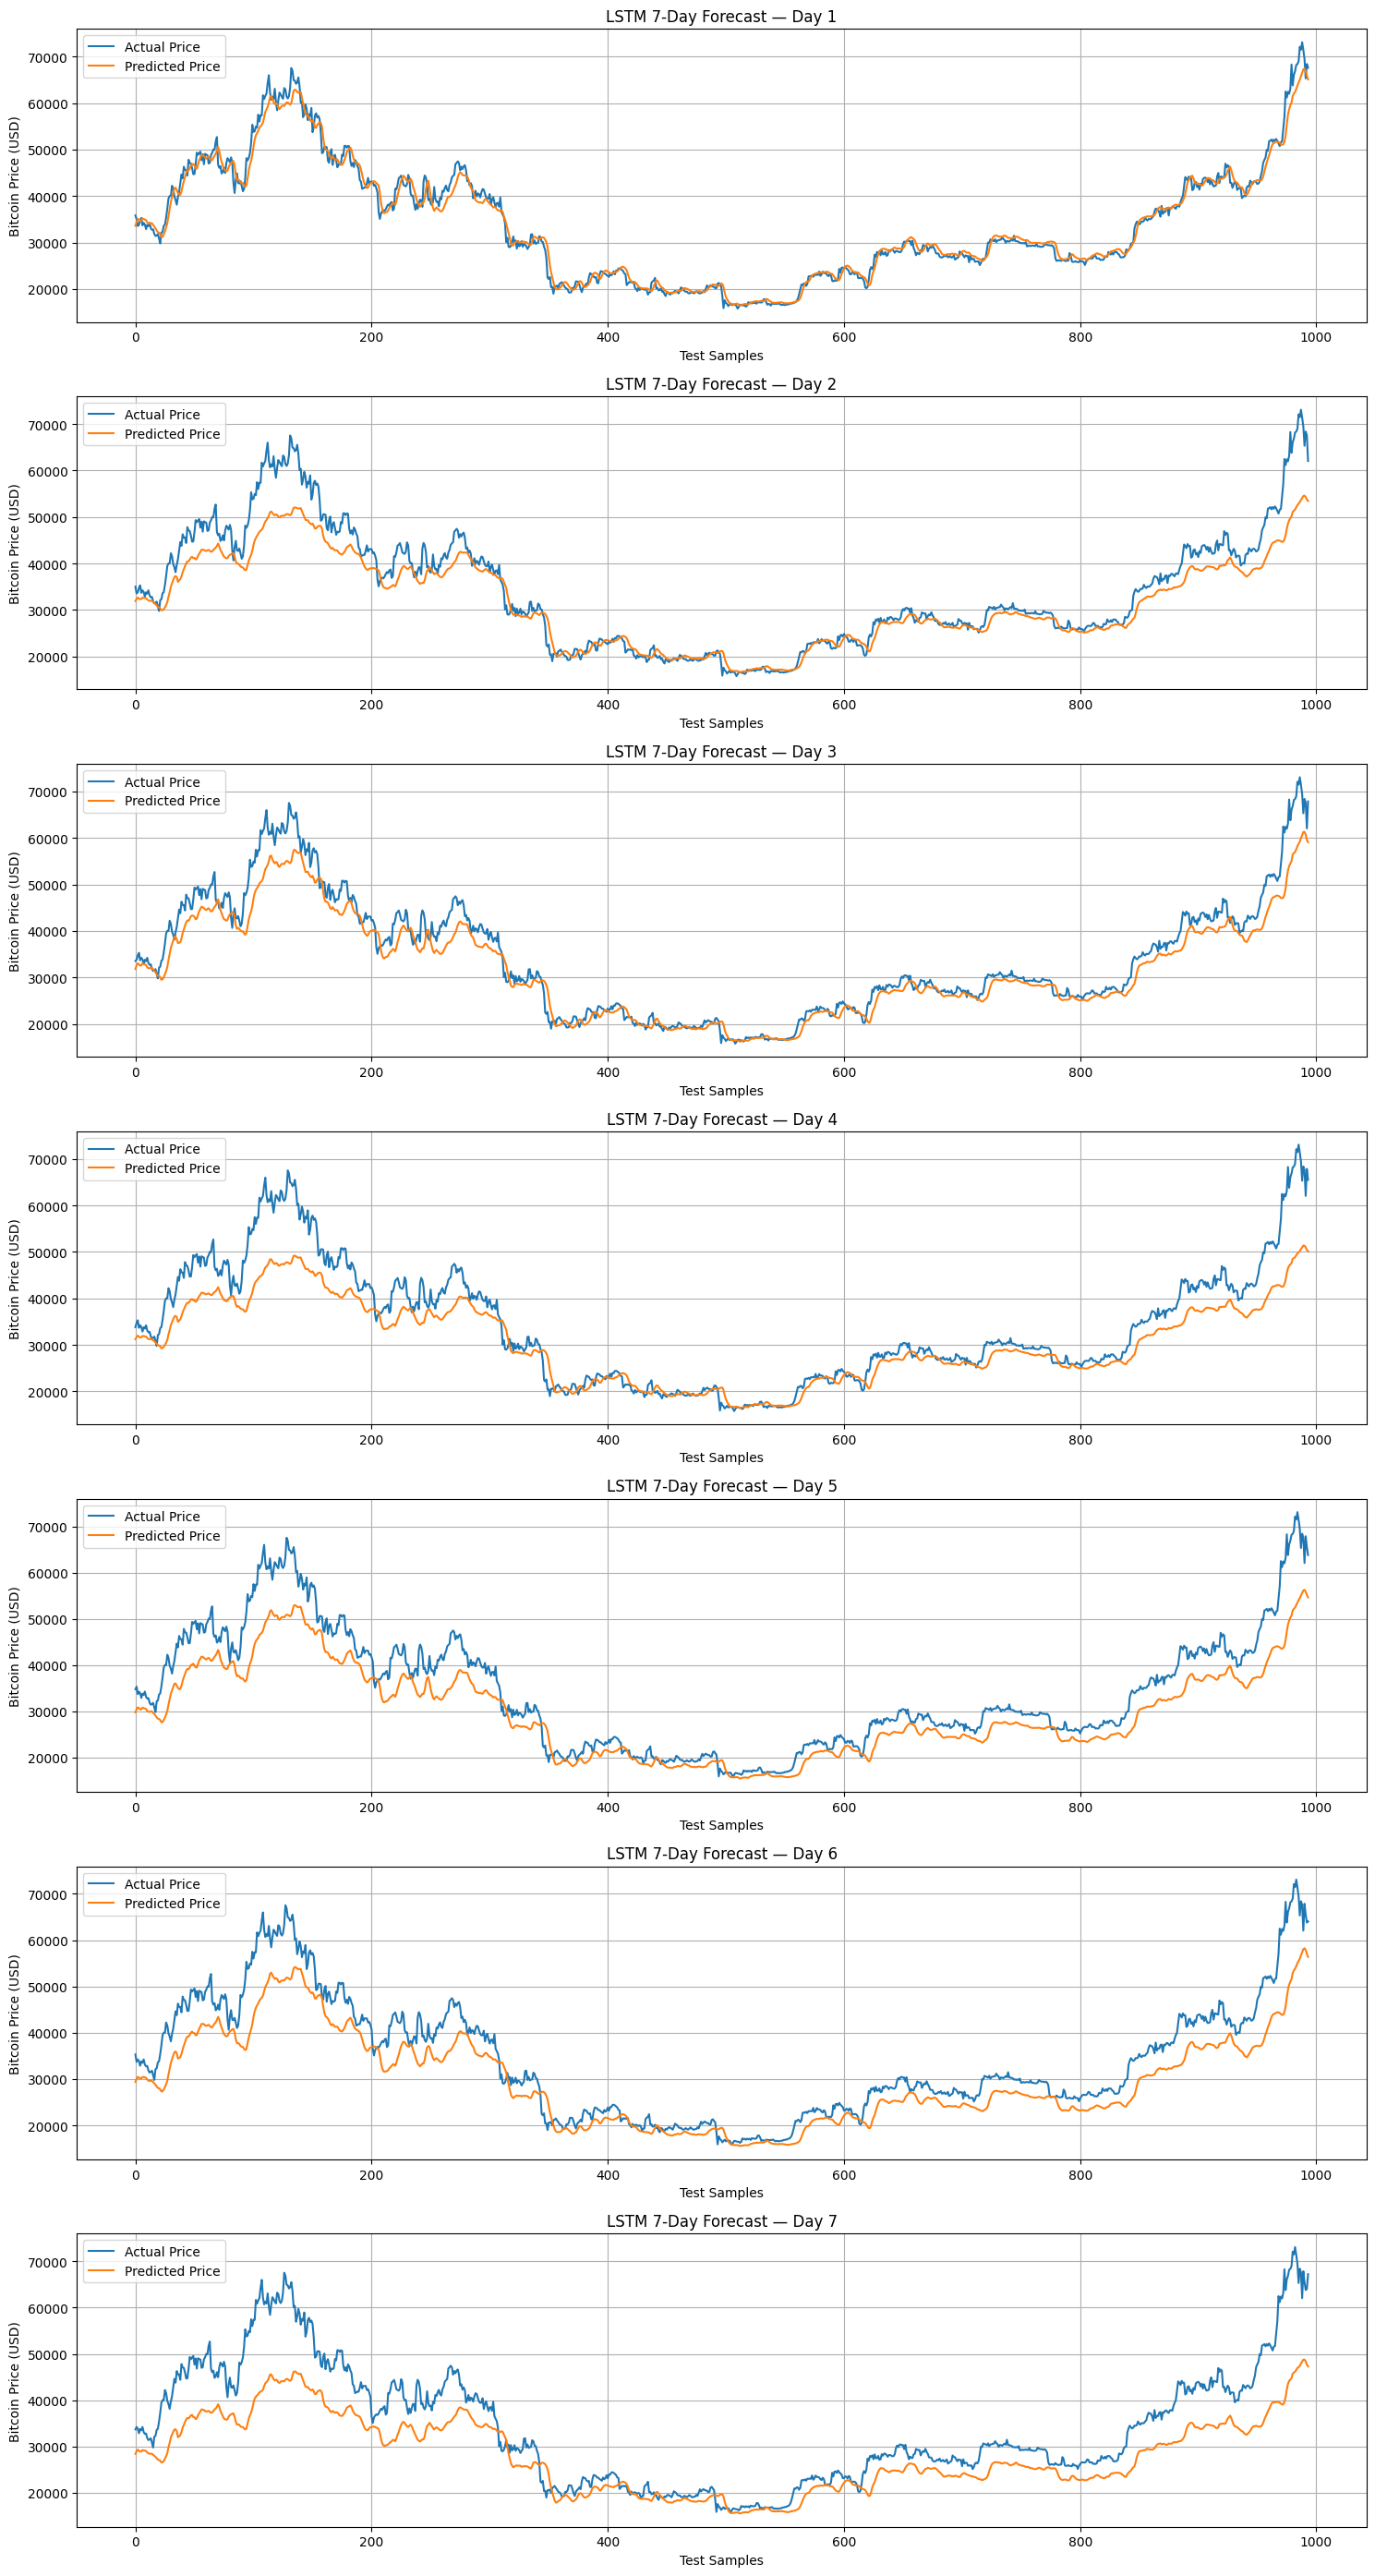

In [46]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(7, 1, figsize=(15, 28))

for day in range(7):
    axes[day].plot(
        actuals_7d_original[:, day],
        label='Actual Price'
    )

    axes[day].plot(
        predictions_7d_original[:, day],
        label='Predicted Price'
    )

    axes[day].set_title(
        f'LSTM 7-Day Forecast — Day {day + 1}'
    )
    axes[day].set_xlabel('Test Samples')
    axes[day].set_ylabel('Bitcoin Price (USD)')
    axes[day].legend()
    axes[day].grid(True)

plt.tight_layout()
plt.show()

In [47]:
import os

In [48]:
results_folder = "/content/drive/MyDrive/cryptocast/results"
os.makedirs(results_folder, exist_ok=True)

lstm_results.to_csv(
    f"{results_folder}/lstm_results.csv",
    index=False
)

print("LSTM results saved successfully!")

LSTM results saved successfully!


In [49]:
import tensorflow as tf

print("Trained LSTM models:")
for name, obj in globals().copy().items():
    if isinstance(obj, tf.keras.Model):
        print(name, obj.output_shape)

print("\nScaler variables:")
for name, obj in globals().copy().items():
    if "scaler" in name.lower():
        print(name, type(obj))

Trained LSTM models:
lstm_1d (None, 1)
lstm_3d (None, 3)
lstm_7d (None, 7)

Scaler variables:
MinMaxScaler <class 'type'>
scaler <class 'sklearn.preprocessing._data.MinMaxScaler'>


In [50]:
import tensorflow as tf

print("Trained LSTM models:")
for name, obj in globals().copy().items():
    if isinstance(obj, tf.keras.Model):
        print(name, obj.output_shape)

print("\nScaler variables:")
for name, obj in globals().copy().items():
    if "scaler" in name.lower():
        print(name, type(obj))

Trained LSTM models:
lstm_1d (None, 1)
lstm_3d (None, 3)
lstm_7d (None, 7)

Scaler variables:
MinMaxScaler <class 'type'>
scaler <class 'sklearn.preprocessing._data.MinMaxScaler'>


In [51]:
import tensorflow as tf

print("Trained LSTM models:")
for name, obj in globals().copy().items():
    if isinstance(obj, tf.keras.Model):
        print(name, obj.output_shape)

print("\nScaler variables:")
for name, obj in globals().copy().items():
    if "scaler" in name.lower():
        print(name, type(obj))

Trained LSTM models:
lstm_1d (None, 1)
lstm_3d (None, 3)
lstm_7d (None, 7)

Scaler variables:
MinMaxScaler <class 'type'>
scaler <class 'sklearn.preprocessing._data.MinMaxScaler'>


In [52]:
import os
import joblib

model_dir = "/content/drive/MyDrive/cryptocast/streamlit/models"
os.makedirs(model_dir, exist_ok=True)

# Save LSTM models
lstm_1d.save(os.path.join(model_dir, "lstm_1d.keras"))
lstm_3d.save(os.path.join(model_dir, "lstm_3d.keras"))
lstm_7d.save(os.path.join(model_dir, "lstm_7d.keras"))

# Save scaler files
for horizon in ["1d", "3d", "7d"]:
    joblib.dump(
        scaler,
        os.path.join(model_dir, f"lstm_scaler_{horizon}.pkl")
    )

print("LSTM models and scaler files saved!")

print([f for f in os.listdir(model_dir) if f.startswith("lstm_")])

LSTM models and scaler files saved!
['lstm_1d.keras', 'lstm_3d.keras', 'lstm_7d.keras', 'lstm_scaler_1d.pkl', 'lstm_scaler_3d.pkl', 'lstm_scaler_7d.pkl']
